<a href="https://colab.research.google.com/github/anupbagale/csv-data-to-image/blob/main/notebooks/03_color_images.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Colour images

A colour image has three values per pixel (red, green and blue), so its array has the shape
height x width x 3. A CSV file is two-dimensional, so we put the three values of each pixel next
to each other: each line holds one image row as `r, g, b, r, g, b, ...`.

To turn the numbers back into an image, the reader also has to know the original shape. We store
it in a comment on the first line, for example `# shape: 512,512,3`.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage import data

os.makedirs("output", exist_ok=True)   # the CSV and image files are written here

In [2]:
image = data.astronaut()      # public domain photo from NASA, RGB order
print("shape:", image.shape)

shape: (512, 512, 3)


## Writing

`reshape` turns the 512 x 512 x 3 array into 512 rows of 1536 values without changing the order
of the numbers. `np.savetxt` writes the rows and adds the shape as a header comment.

In [3]:
csv_path = "output/astronaut.csv"
rows = image.reshape(image.shape[0], -1)
shape = ",".join(str(n) for n in image.shape)
np.savetxt(csv_path, rows, fmt="%d", delimiter=",", header=f"shape: {shape}", comments="# ")

with open(csv_path) as f:
    print(f.readline().strip())
    print(f.readline()[:60], "...")
print("rows written:", rows.shape[0], " values per row:", rows.shape[1])

# shape: 512,512,3
154,147,151,109,103,124,63,58,102,54,51,98,76,76,106,100,100 ...
rows written: 512  values per row: 1536


The first pixel of the first row has the values 154, 147, 151, a light grey. The next three
numbers are the second pixel, and so on.

## Reading

In [4]:
with open(csv_path) as f:
    shape = tuple(int(n) for n in f.readline().split("shape:")[1].split(","))

values = np.loadtxt(csv_path, delimiter=",", comments="#", dtype=np.uint8)
restored = values.reshape(shape)
print("shape:", restored.shape)
print("identical to the original:", np.array_equal(restored, image))

shape: (512, 512, 3)
identical to the original: True


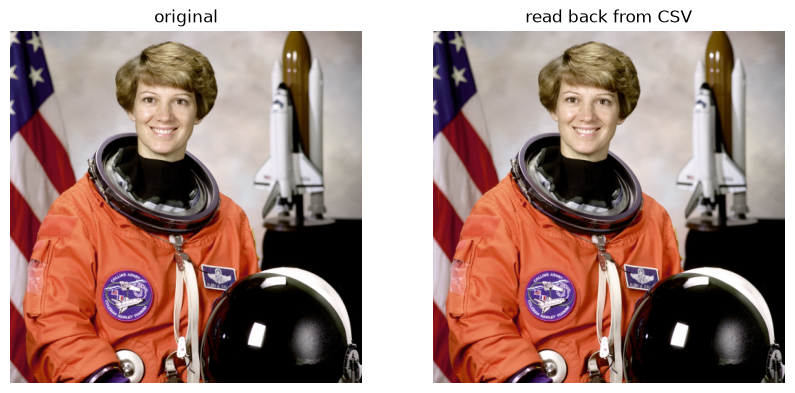

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(image); ax[0].set_title("original")
ax[1].imshow(restored); ax[1].set_title("read back from CSV")
for a in ax:
    a.axis("off")
plt.show()

## Watch out for OpenCV's colour order

`cv2.imread` returns colour images in **BGR** order, not RGB. If an image is read with OpenCV and
written to CSV as it is, the first value of each pixel is blue, and any other program that expects
RGB will swap red and blue. Converting with `cv2.cvtColor(img, cv2.COLOR_BGR2RGB)` first avoids
this.

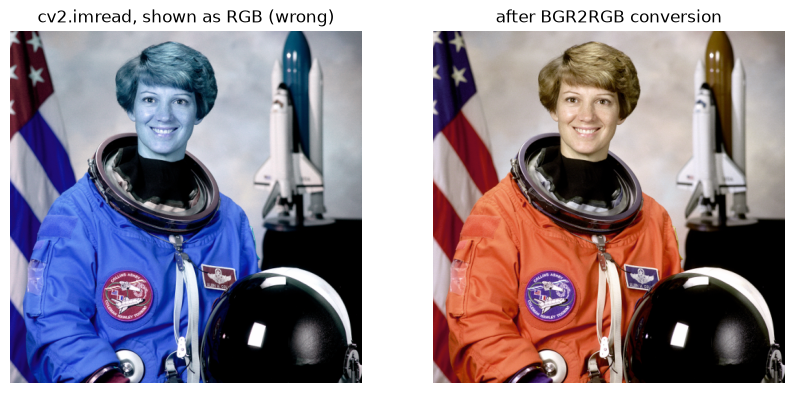

In [6]:
cv2.imwrite("output/astronaut.png", cv2.cvtColor(image, cv2.COLOR_RGB2BGR))   # OpenCV writes BGR
read_bgr = cv2.imread("output/astronaut.png")
read_rgb = cv2.cvtColor(read_bgr, cv2.COLOR_BGR2RGB)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(read_bgr); ax[0].set_title("cv2.imread, shown as RGB (wrong)")
ax[1].imshow(read_rgb); ax[1].set_title("after BGR2RGB conversion")
for a in ax:
    a.axis("off")
plt.show()

## The command-line tool

`csv_image.py` in this repository does all of the above for any image file, grayscale or colour:

```bash
python csv_image.py to-csv photo.png photo.csv
python csv_image.py to-image photo.csv restored.png
```

It converts between OpenCV's BGR order and RGB automatically, so the CSV file always holds red,
green, blue.